<a href="https://colab.research.google.com/github/Ashwini4856/BIS_LAB/blob/main/grey_wolf_optimizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

OPTIMAL JOB SCHEDULING
----------------------
Job 1 -> Server 3
Job 2 -> Server 1
Job 3 -> Server 2
Job 4 -> Server 2
Job 5 -> Server 1

Server Workloads:
Server 1 : 11.0
Server 2 : 11.0
Server 3 : 8.0

Minimum Makespan: 11.0


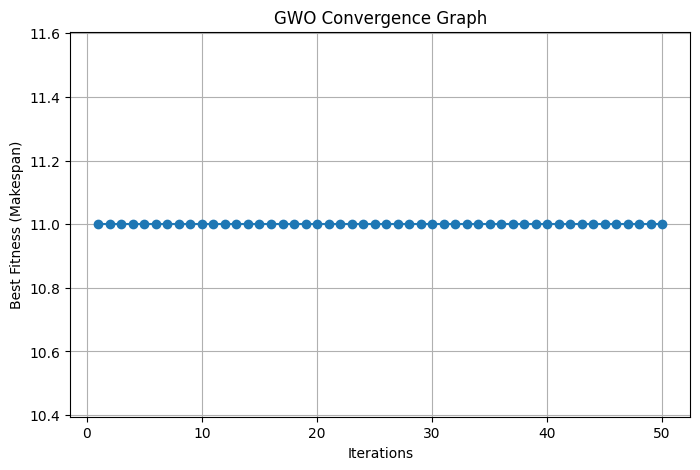

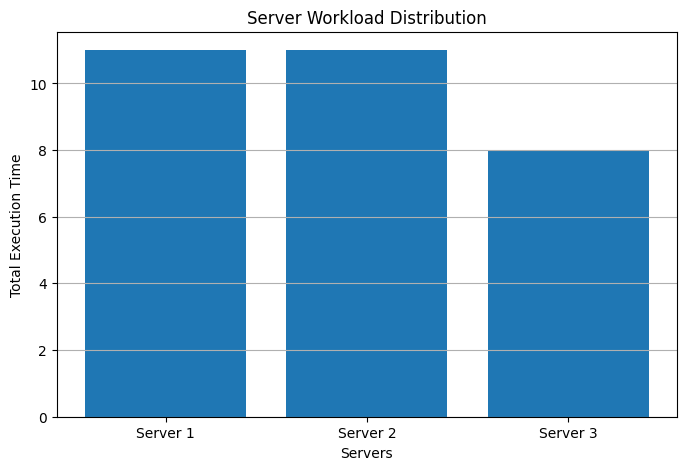

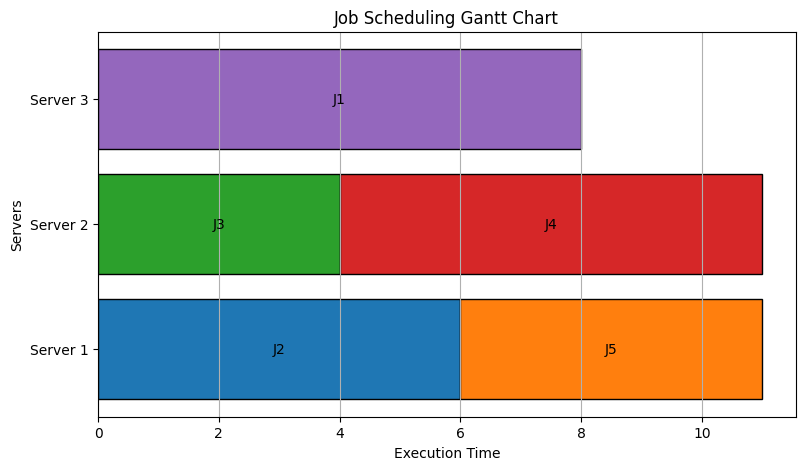

In [2]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Problem setup
jobs = [8, 6, 4, 7, 5]
num_servers = 3
num_wolves = 10
max_iterations = 50
num_jobs = len(jobs)

np.random.seed(42)

# 2. Initialize wolves
wolves = np.random.uniform(
    0, num_servers - 1, (num_wolves, num_jobs)
)

# Convert continuous position into server assignment
def decode(position):
    return np.clip(
        np.rint(position).astype(int),
        0, num_servers - 1
    )

# 3. Fitness function
def fitness(position):
    assignment = decode(position)
    loads = np.zeros(num_servers)

    for i in range(num_jobs):
        loads[assignment[i]] += jobs[i]

    return max(loads)

# 4. Grey Wolf Optimization
best_fitness = float('inf')
best_position = None
convergence = []

for iteration in range(max_iterations):

    scores = np.array([fitness(w) for w in wolves])

    sorted_indices = np.argsort(scores)

    alpha = wolves[sorted_indices[0]].copy()
    beta = wolves[sorted_indices[1]].copy()
    delta = wolves[sorted_indices[2]].copy()

    # Store global best
    if scores[sorted_indices[0]] < best_fitness:
        best_fitness = scores[sorted_indices[0]]
        best_position = alpha.copy()

    convergence.append(best_fitness)

    # Control parameter
    a = 2 - 2 * iteration / max_iterations

    # Update wolf positions
    new_wolves = np.zeros_like(wolves)

    for i in range(num_wolves):
        X1 = np.zeros(num_jobs)
        X2 = np.zeros(num_jobs)
        X3 = np.zeros(num_jobs)

        for j in range(num_jobs):

            r1, r2 = np.random.rand(), np.random.rand()
            A1 = 2 * a * r1 - a
            C1 = 2 * r2
            D1 = abs(C1 * alpha[j] - wolves[i][j])
            X1[j] = alpha[j] - A1 * D1

            r1, r2 = np.random.rand(), np.random.rand()
            A2 = 2 * a * r1 - a
            C2 = 2 * r2
            D2 = abs(C2 * beta[j] - wolves[i][j])
            X2[j] = beta[j] - A2 * D2

            r1, r2 = np.random.rand(), np.random.rand()
            A3 = 2 * a * r1 - a
            C3 = 2 * r2
            D3 = abs(C3 * delta[j] - wolves[i][j])
            X3[j] = delta[j] - A3 * D3

        new_wolves[i] = (X1 + X2 + X3) / 3

    wolves = np.clip(new_wolves, 0, num_servers - 1)

    # Preserve the best solution
    wolves[0] = best_position

# 5. Final solution
best_assignment = decode(best_position)

server_loads = np.zeros(num_servers)
server_jobs = [[] for _ in range(num_servers)]

for i in range(num_jobs):
    s = best_assignment[i]
    server_loads[s] += jobs[i]
    server_jobs[s].append(i)

print("OPTIMAL JOB SCHEDULING")
print("----------------------")

for i in range(num_jobs):
    print("Job", i + 1, "-> Server",
          best_assignment[i] + 1)

print("\nServer Workloads:")
for i in range(num_servers):
    print("Server", i + 1, ":", server_loads[i])

print("\nMinimum Makespan:", best_fitness)

# 6. Graph 1: Convergence graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, max_iterations + 1),
         convergence, marker='o')

plt.title("GWO Convergence Graph")
plt.xlabel("Iterations")
plt.ylabel("Best Fitness (Makespan)")
plt.grid(True)
plt.show()

# 7. Graph 2: Server workload graph
plt.figure(figsize=(8, 5))

plt.bar(
    [f"Server {i+1}" for i in range(num_servers)],
    server_loads
)

plt.title("Server Workload Distribution")
plt.xlabel("Servers")
plt.ylabel("Total Execution Time")
plt.grid(axis='y')
plt.show()

# 8. Graph 3: Gantt chart
plt.figure(figsize=(9, 5))

for s in range(num_servers):
    current_time = 0

    for job_index in server_jobs[s]:
        duration = jobs[job_index]

        plt.barh(
            s, duration,
            left=current_time,
            edgecolor='black',
            label=f"Job {job_index+1}"
        )

        plt.text(
            current_time + duration / 2,
            s,
            f"J{job_index+1}",
            ha='center',
            va='center'
        )

        current_time += duration

plt.yticks(
    range(num_servers),
    [f"Server {i+1}" for i in range(num_servers)]
)

plt.title("Job Scheduling Gantt Chart")
plt.xlabel("Execution Time")
plt.ylabel("Servers")
plt.grid(axis='x')
plt.show()


ANT COLONY OPTIMIZATION
-----------------------
Job 1 -> Server 3
Job 2 -> Server 1
Job 3 -> Server 1
Job 4 -> Server 3
Job 5 -> Server 1
Job 6 -> Server 2
Job 7 -> Server 2

Server Workloads:
Server 1 : 15.0
Server 2 : 13.0
Server 3 : 15.0

Minimum Makespan: 15.0


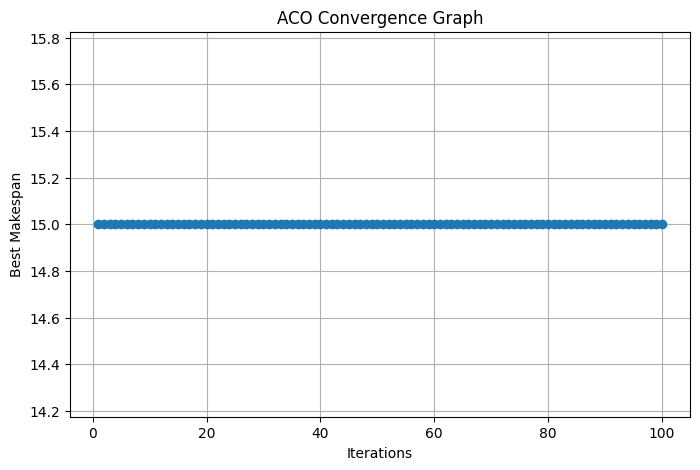

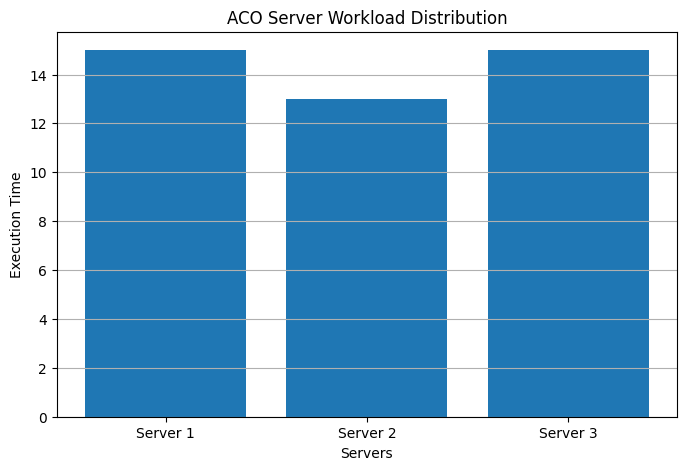

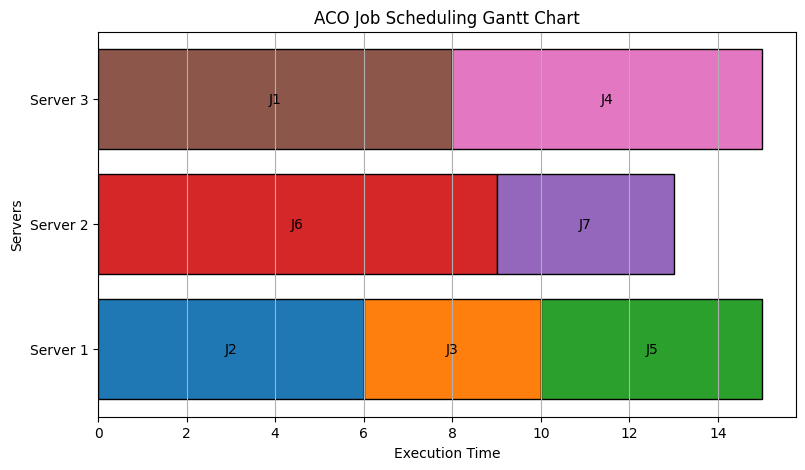

In [4]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Problem setup
jobs = [8, 6, 4, 7, 5,9,4]
num_servers = 3
num_jobs = len(jobs)

# ACO parameters
num_ants = 30
iterations = 100
alpha = 1
beta = 2
evaporation = 0.5
Q = 100

np.random.seed(42)

# 2. Initialize pheromone
pheromone = np.ones((num_jobs, num_servers))

# Process larger jobs first
job_order = sorted(
    range(num_jobs),
    key=lambda x: jobs[x],
    reverse=True
)

# 3. Fitness function
def fitness(solution):
    loads = np.zeros(num_servers)

    for j in range(num_jobs):
        loads[solution[j]] += jobs[j]

    return max(loads)

# 4. ACO algorithm
best_solution = None
best_fitness = float('inf')
convergence = []

for iteration in range(iterations):

    all_solutions = []
    all_scores = []

    for ant in range(num_ants):

        solution = [-1] * num_jobs
        loads = np.zeros(num_servers)

        # Each ant assigns jobs to servers
        for j in job_order:

            probabilities = []

            for s in range(num_servers):

                # Heuristic: prefer less-loaded servers
                heuristic = 1 / (1 + loads[s] + jobs[j])

                value = (
                    pheromone[j, s] ** alpha
                    * heuristic ** beta
                )

                probabilities.append(value)

            probabilities = np.array(probabilities)
            probabilities /= probabilities.sum()

            # Select a server based on probability
            selected = np.random.choice(
                num_servers,
                p=probabilities
            )

            solution[j] = selected
            loads[selected] += jobs[j]

        score = fitness(solution)

        all_solutions.append(solution.copy())
        all_scores.append(score)

        if score < best_fitness:
            best_fitness = score
            best_solution = solution.copy()

    # 5. Pheromone evaporation
    pheromone *= (1 - evaporation)

    # 6. Pheromone update
    for solution, score in zip(all_solutions, all_scores):

        deposit = Q / score

        for j in range(num_jobs):
            s = solution[j]
            pheromone[j, s] += deposit

    # Reinforce the best solution found so far
    for j in range(num_jobs):
        s = best_solution[j]
        pheromone[j, s] += Q / best_fitness

    convergence.append(best_fitness)

# 7. Display final solution
server_loads = np.zeros(num_servers)
server_jobs = [[] for _ in range(num_servers)]

print("ANT COLONY OPTIMIZATION")
print("-----------------------")

for j in range(num_jobs):
    s = best_solution[j]
    server_loads[s] += jobs[j]
    server_jobs[s].append(j)

    print("Job", j + 1, "-> Server", s + 1)

print("\nServer Workloads:")

for s in range(num_servers):
    print("Server", s + 1, ":", server_loads[s])

print("\nMinimum Makespan:", best_fitness)

# 8. Graph 1: Convergence graph
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, iterations + 1),
    convergence,
    marker='o'
)

plt.title("ACO Convergence Graph")
plt.xlabel("Iterations")
plt.ylabel("Best Makespan")
plt.grid(True)
plt.show()

# 9. Graph 2: Server workload graph
plt.figure(figsize=(8, 5))

plt.bar(
    [f"Server {s+1}" for s in range(num_servers)],
    server_loads
)

plt.title("ACO Server Workload Distribution")
plt.xlabel("Servers")
plt.ylabel("Execution Time")
plt.grid(axis='y')
plt.show()

# 10. Graph 3: Gantt chart
plt.figure(figsize=(9, 5))

for s in range(num_servers):

    current_time = 0

    for j in server_jobs[s]:

        duration = jobs[j]

        plt.barh(
            s,
            duration,
            left=current_time,
            edgecolor='black'
        )

        plt.text(
            current_time + duration / 2,
            s,
            f"J{j+1}",
            ha='center',
            va='center'
        )

        current_time += duration

plt.yticks(
    range(num_servers),
    [f"Server {s+1}" for s in range(num_servers)]
)

plt.title("ACO Job Scheduling Gantt Chart")
plt.xlabel("Execution Time")
plt.ylabel("Servers")
plt.grid(axis='x')
plt.show()
